# Setup and Loading data (cora)

In [ ]:
%pip install -q torch_geometric scikit-learn pandas matplotlib

In [ ]:
from pathlib import Path
import logging
import sys

PROJECT = Path("/content/cora_gnn_experiment")
PACKAGE = PROJECT / "gnn_lab"

PACKAGE.mkdir(parents=True, exist_ok=True)
(PROJECT / "outputs").mkdir(exist_ok=True)

(PACKAGE / "__init__.py").write_text(
    '"""Modular Cora node-classification experiments using PyTorch Geometric."""\n'
)

# Allow notebook cells to import the modules created below.
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
    datefmt="%H:%M:%S",
    stream=sys.stdout,
    force=True,
)

# The initial directory tree is updated automatically after the experiment.
tree_text = """cora_gnn_experiment/
├── directory_tree.txt
├── gnn_lab/
│   ├── __init__.py
│   ├── data.py
│   ├── models.py
│   ├── engine.py
│   └── visualization.py
└── outputs/
"""
(PROJECT / "directory_tree.txt").write_text(tree_text)
print(tree_text)

cora_gnn_experiment/
├── directory_tree.txt
├── gnn_lab/
│   ├── __init__.py
│   ├── data.py
│   ├── models.py
│   ├── engine.py
│   └── visualization.py
└── outputs/



Cora’s public split contains:

    140 training nodes;
    500 validation nodes;
    1,000 test nodes.

The remaining nodes are not supervised or scored, but still participate in message passing.

This is transductive learning: all node features and graph connections are visible, while only training labels contribute to the training loss.

In [ ]:
%%writefile /content/cora_gnn_experiment/gnn_lab/data.py
"""Load and validate a single-graph node-classification dataset."""

import logging
from pathlib import Path

import torch
from torch_geometric.datasets import Planetoid
from torch_geometric.transforms import NormalizeFeatures

LOGGER = logging.getLogger(__name__)


def validate_splits(data):
    """Check that supervised splits are nonempty, boolean, and disjoint.

    Args:
        data: PyG Data object with labels and train/val/test masks.

    Raises:
        ValueError: If any mask has an invalid shape/type or splits overlap.

    Not every node must belong to a supervised split in transductive learning.
    """
    masks = []
    for name in ("train_mask", "val_mask", "test_mask"):
        mask = getattr(data, name, None)
        if mask is None:
            raise ValueError(f"Dataset is missing {name}.")
        if mask.dtype != torch.bool or mask.shape != (data.num_nodes,):
            raise ValueError(f"{name} must be a boolean vector of length num_nodes.")
        if not mask.any().item():
            raise ValueError(f"{name} must contain at least one node.")
        masks.append(mask)

    membership_count = torch.stack(masks).sum(dim=0)
    if (membership_count > 1).any().item():
        raise ValueError("Training, validation, and test masks overlap.")


def load_cora(root):
    """Download Cora if necessary and return (graph, number_of_classes).

    Feature normalization rescales each node's nonnegative feature vector
    to sum to one. The dataset's fixed public split is preserved.

    Args:
        root: Directory used for downloaded and processed dataset files.
    """
    LOGGER.info("Loading Cora into %s", root)
    dataset = Planetoid(
        root=str(Path(root)),
        name="Cora",
        split="public",
        transform=NormalizeFeatures(),
    )
    data = dataset[0]
    validate_splits(data)

    LOGGER.info(
        "Loaded Cora: nodes=%d, edge entries=%d, features=%d, classes=%d",
        data.num_nodes,
        data.num_edges,
        data.num_node_features,
        dataset.num_classes,
    )
    LOGGER.info(
        "Supervised nodes: train=%d, validation=%d, test=%d",
        data.train_mask.sum().item(),
        data.val_mask.sum().item(),
        data.test_mask.sum().item(),
    )
    return data, dataset.num_classes

Writing /content/cora_gnn_experiment/gnn_lab/data.py


# Defining model architecture

All models use this shared structure:

        

        
text
        
    
  
      

Node features
    ↓
Graph layer
    ↓
ReLU
    ↓
Dropout
    ↓
Graph layer
    ↓
Class logits

The only architectural switch is the graph-layer factory.

The vanilla implementation explicitly includes self-loops. GCN and GAT also include self-loops through their PyG implementations.

In [ ]:
%%writefile /content/cora_gnn_experiment/gnn_lab/models.py
"""Interchangeable sum-GNN, GCN, and GAT layers in a shared classifier."""

import torch
import torch.nn.functional as F
from torch import nn
from torch_geometric.nn import MessagePassing, GCNConv, GATConv
from torch_geometric.utils import add_remaining_self_loops


class SumGraphConv(MessagePassing):
    """Apply an unnormalized sum over transformed neighboring node features.

    For node i:
        output_i = sum_{j in neighbors(i) union {i}} W x_j + b

    A bias is added AFTER aggregation so it is not multiplied by node degree.
    This layer intentionally has no degree normalization or attention.
    """

    def __init__(self, in_channels, out_channels):
        """Create the feature projection and output bias."""
        super().__init__(aggr="add")
        self.linear = nn.Linear(in_channels, out_channels, bias=False)
        self.bias = nn.Parameter(torch.zeros(out_channels))
        self.reset_parameters()

    def reset_parameters(self):
        """Initialize weights consistently with common graph-layer defaults."""
        nn.init.xavier_uniform_(self.linear.weight)
        nn.init.zeros_(self.bias)

    def forward(self, x, edge_index):
        """Return updated features with shape [num_nodes, out_channels]."""
        # Preserve existing self-loops instead of blindly adding duplicates.
        edge_index, _ = add_remaining_self_loops(
            edge_index, num_nodes=x.size(0)
        )
        transformed = self.linear(x)
        aggregated = self.propagate(edge_index, x=transformed)
        return aggregated + self.bias

    def message(self, x_j):
        """Send the projected source-node feature along each edge."""
        return x_j


def make_graph_layer(kind, in_channels, out_channels, gat_heads=1):
    """Build a graph layer with a common (x, edge_index) interface.

    GAT averages heads rather than concatenating them, preserving output width.
    Increasing heads therefore preserves the interface but increases parameters.

    Raises:
        ValueError: If kind is unsupported or gat_heads is invalid.
    """
    kind = kind.lower()

    if kind == "sum":
        return SumGraphConv(in_channels, out_channels)

    if kind == "gcn":
        return GCNConv(
            in_channels,
            out_channels,
            normalize=True,
            add_self_loops=True,
            cached=False,
        )

    if kind == "gat":
        if gat_heads < 1:
            raise ValueError("gat_heads must be at least 1.")
        return GATConv(
            in_channels,
            out_channels,
            heads=gat_heads,
            concat=False,
            # Shared feature dropout is applied by the classifier instead.
            # Keeping attention dropout off reduces extra experimental factors.
            dropout=0.0,
            add_self_loops=True,
        )

    raise ValueError(f"Unknown layer kind: {kind!r}. Use sum, gcn, or gat.")


class NodeClassifier(nn.Module):
    """Two-layer node classifier with a replaceable graph-layer architecture."""

    def __init__(
        self,
        in_channels,
        hidden_channels,
        out_channels,
        kind="gcn",
        dropout=0.5,
        gat_heads=1,
    ):
        """Construct two graph layers sharing the chosen architecture."""
        super().__init__()
        self.conv1 = make_graph_layer(
            kind, in_channels, hidden_channels, gat_heads
        )
        self.conv2 = make_graph_layer(
            kind, hidden_channels, out_channels, gat_heads
        )
        self.dropout = dropout

    def encode(self, x, edge_index):
        """Return hidden node representations before dropout."""
        return F.relu(self.conv1(x, edge_index))

    def forward(self, x, edge_index):
        """Return raw class logits; cross-entropy applies log-softmax internally."""
        hidden = self.encode(x, edge_index)
        hidden = F.dropout(
            hidden, p=self.dropout, training=self.training
        )
        return self.conv2(hidden, edge_index)


def count_parameters(model):
    """Return the number of trainable scalar parameters."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

Writing /content/cora_gnn_experiment/gnn_lab/models.py


# Training Pipeline

What to inspect while learning:

    SumGraphConv.message() defines what travels along an edge.
    aggr="add" defines how incoming messages are combined.
    GCNConv introduces degree-based normalization.
    GATConv learns edge-specific attention coefficients.
    NodeClassifier does not need to know how a graph layer implements aggregation.


The training code:

    trains using only training labels;
    chooses checkpoints using validation loss;
    restores the best checkpoint;
    evaluates the held-out test nodes once per run;
    saves checkpoints and logs progress.

The training loss is measured in training mode with dropout. Validation loss is measured afterward in evaluation mode, so the two curves need not match exactly.

In [ ]:
%%writefile /content/cora_gnn_experiment/gnn_lab/engine.py
"""Reproducible full-batch training and held-out evaluation for node classifiers."""

from dataclasses import asdict, dataclass
import logging
from pathlib import Path
import random
import time

import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score

LOGGER = logging.getLogger(__name__)


@dataclass(frozen=True)
class TrainConfig:
    """Shared model/training settings used for every architecture."""

    hidden_channels: int = 32
    dropout: float = 0.5
    gat_heads: int = 1
    learning_rate: float = 0.01
    weight_decay: float = 5e-4
    max_epochs: int = 300
    patience: int = 50
    log_every: int = 25


def seed_everything(seed):
    """Seed Python, NumPy, and PyTorch.

    CUDA graph reductions may still be nondeterministic. Seeds improve
    repeatability but do not promise bitwise-identical GPU results.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def train_one_epoch(model, data, optimizer):
    """Update model weights using cross-entropy on training nodes only.

    Raises:
        RuntimeError: If loss is non-finite, indicating numerical instability.
    """
    model.train()
    optimizer.zero_grad(set_to_none=True)

    logits = model(data.x, data.edge_index)
    loss = F.cross_entropy(
        logits[data.train_mask], data.y[data.train_mask]
    )

    if not torch.isfinite(loss).item():
        raise RuntimeError(
            "Training loss became non-finite. Try a smaller learning rate, "
            "especially for the unnormalized sum GNN."
        )

    loss.backward()
    optimizer.step()
    return loss.item()


@torch.no_grad()
def evaluate_split(model, data, mask):
    """Return loss, accuracy, macro-F1, labels, and predictions for one split.

    The provided mask controls which labels are read for evaluation.
    Predictions use the full graph, as required by the transductive setup.
    """
    model.eval()
    logits = model(data.x, data.edge_index)
    split_logits = logits[mask]
    labels = data.y[mask]

    loss = F.cross_entropy(split_logits, labels).item()
    y_true = labels.cpu().numpy()
    y_pred = split_logits.argmax(dim=-1).cpu().numpy()

    return {
        "loss": loss,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=list(range(logits.size(-1))),
            average="macro",
            zero_division=0,
        ),
        "y_true": y_true,
        "y_pred": y_pred,
    }


def synchronize_device(device):
    """Wait for queued CUDA work so wall-clock timing is meaningful."""
    if device.type == "cuda":
        torch.cuda.synchronize(device)


def fit(model, data, config, checkpoint_path, run_name):
    """Train with validation-loss early stopping and restore the best weights.

    Args:
        model: Node classifier already on the same device as data.
        data: PyG graph containing train_mask and val_mask.
        config: TrainConfig instance.
        checkpoint_path: Destination for the selected checkpoint.
        run_name: Human-readable identifier used in terminal logs.

    Returns:
        Dictionary containing epoch history, selected epoch, and fit time.

    Side effects:
        Updates model weights and writes a CPU-portable checkpoint.
        Never accesses test labels.
    """
    if config.max_epochs < 1 or config.patience < 1 or config.log_every < 1:
        raise ValueError("max_epochs, patience, and log_every must be positive.")

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=config.learning_rate,
        weight_decay=config.weight_decay,
    )

    best_loss = float("inf")
    best_epoch = 0
    best_state = None
    stale_epochs = 0
    history = []

    LOGGER.info("Starting %s on %s", run_name, data.x.device)
    synchronize_device(data.x.device)
    started = time.perf_counter()

    for epoch in range(1, config.max_epochs + 1):
        train_loss = train_one_epoch(model, data, optimizer)
        validation = evaluate_split(model, data, data.val_mask)

        if not np.isfinite(validation["loss"]):
            raise RuntimeError(
                f"{run_name}: validation loss became non-finite. "
                "Try a lower learning rate."
            )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": validation["loss"],
            "val_accuracy": validation["accuracy"],
        })

        # Store independent CPU copies: state_dict() alone references live weights.
        if validation["loss"] < best_loss:
            best_loss = validation["loss"]
            best_epoch = epoch
            best_state = {
                name: tensor.detach().cpu().clone()
                for name, tensor in model.state_dict().items()
            }
            stale_epochs = 0
        else:
            stale_epochs += 1

        if epoch == 1 or epoch % config.log_every == 0:
            LOGGER.info(
                "%s | epoch=%03d train_loss=%.4f val_loss=%.4f val_acc=%.3f",
                run_name,
                epoch,
                train_loss,
                validation["loss"],
                validation["accuracy"],
            )

        if stale_epochs >= config.patience:
            LOGGER.info(
                "%s | early stopping at epoch %d; best epoch=%d",
                run_name, epoch, best_epoch,
            )
            break

    synchronize_device(data.x.device)
    fit_seconds = time.perf_counter() - started

    model.load_state_dict(best_state)
    model.eval()

    checkpoint_path = Path(checkpoint_path)
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(
        {
            "model_state": best_state,
            "config": asdict(config),
            "run_name": run_name,
            "best_epoch": best_epoch,
            "best_val_loss": best_loss,
            "in_channels": data.num_node_features,
            "out_channels": int(data.y[data.train_mask].max().item()) + 1,
        },
        checkpoint_path,
    )

    LOGGER.info(
        "Completed %s | best_epoch=%d val_loss=%.4f fit_time=%.2fs | saved=%s",
        run_name, best_epoch, best_loss, fit_seconds, checkpoint_path,
    )
    return {
        "history": history,
        "best_epoch": best_epoch,
        "epochs_run": len(history),
        "fit_seconds": fit_seconds,
    }

Writing /content/cora_gnn_experiment/gnn_lab/engine.py


## evaluation and visulation utils

In [ ]:
%%writefile /content/cora_gnn_experiment/gnn_lab/visualization.py
"""Diagnostic plots for architecture comparisons and held-out predictions."""

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix


def plot_learning_curves(histories, seed, output_dir):
    """Plot loss and validation accuracy for all architectures at one fixed seed."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    for (architecture, run_seed), history in histories.items():
        if run_seed != seed:
            continue

        epochs = [row["epoch"] for row in history]
        line, = axes[0].plot(
            epochs,
            [row["train_loss"] for row in history],
            label=f"{architecture}: train",
        )
        axes[0].plot(
            epochs,
            [row["val_loss"] for row in history],
            linestyle="--",
            color=line.get_color(),
            label=f"{architecture}: validation",
        )
        axes[1].plot(
            epochs,
            [row["val_accuracy"] for row in history],
            label=architecture,
        )

    axes[0].set(title=f"Loss — seed {seed}", xlabel="Epoch", ylabel="Cross-entropy")
    axes[1].set(
        title=f"Validation accuracy — seed {seed}",
        xlabel="Epoch",
        ylabel="Accuracy",
    )
    for axis in axes:
        axis.grid(alpha=0.25)
        axis.legend()

    fig.tight_layout()
    fig.savefig(Path(output_dir) / "learning_curves.png", dpi=150)
    plt.show()


def plot_test_accuracy(results, output_dir):
    """Show mean test accuracy, sample standard deviation, and individual runs."""
    order = list(results["architecture"].unique())
    grouped = results.groupby("architecture")["test_accuracy"]
    means = grouped.mean().reindex(order)
    stds = grouped.std().reindex(order).fillna(0)

    fig, ax = plt.subplots(figsize=(7, 4))
    positions = np.arange(len(order))
    ax.bar(
        positions, means.to_numpy(), yerr=stds.to_numpy(),
        capsize=6, alpha=0.65,
    )

    for position, architecture in zip(positions, order):
        values = results.loc[
            results["architecture"] == architecture, "test_accuracy"
        ].to_numpy()
        offsets = np.linspace(-0.08, 0.08, len(values))
        ax.scatter(position + offsets, values, color="black", s=25, zorder=3)

    ax.set_xticks(positions, order)
    ax.set(
        ylim=(0, 1),
        ylabel="Test accuracy",
        title="Mean ± sample standard deviation; dots are individual seeds",
    )
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    fig.savefig(Path(output_dir) / "test_accuracy.png", dpi=150)
    plt.show()


def plot_confusion_matrices(predictions, seed, num_classes, output_dir):
    """Plot row-normalized test confusion matrices at a preselected seed."""
    selected = [
        (architecture, values)
        for (architecture, run_seed), values in predictions.items()
        if run_seed == seed
    ]
    fig, axes = plt.subplots(
        1, len(selected), figsize=(5 * len(selected), 4), squeeze=False
    )

    for ax, (architecture, values) in zip(axes.ravel(), selected):
        matrix = confusion_matrix(
            values["y_true"],
            values["y_pred"],
            labels=np.arange(num_classes),
            normalize="true",
        )
        ConfusionMatrixDisplay(
            matrix, display_labels=np.arange(num_classes)
        ).plot(
            ax=ax,
            cmap="Blues",
            colorbar=False,
            values_format=".2f",
            im_kw={"vmin": 0, "vmax": 1},
        )
        ax.set_title(f"{architecture} — seed {seed}")

    fig.tight_layout()
    fig.savefig(Path(output_dir) / "confusion_matrices.png", dpi=150)
    plt.show()

Writing /content/cora_gnn_experiment/gnn_lab/visualization.py


In [ ]:
import json
import platform

import pandas as pd
import torch
import torch_geometric
from dataclasses import asdict
from IPython.display import display

from gnn_lab.data import load_cora
from gnn_lab.models import NodeClassifier, count_parameters
from gnn_lab.engine import (
    TrainConfig,
    seed_everything,
    fit,
    evaluate_split,
)
from gnn_lab.visualization import (
    plot_learning_curves,
    plot_test_accuracy,
    plot_confusion_matrices,
)

LOGGER = logging.getLogger("experiment")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ARCHITECTURES = ("sum", "gcn", "gat")
SEEDS = (0, 1, 2)

CONFIG = TrainConfig(
    hidden_channels=32,
    dropout=0.5,
    gat_heads=1,
    learning_rate=0.01,
    weight_decay=5e-4,
    max_epochs=300,
    patience=50,
    log_every=25,
)

# Quick smoke-test alternative:
# SEEDS = (0,)
# CONFIG = TrainConfig(max_epochs=30, patience=10, log_every=10)

OUTPUT_DIR = PROJECT / "outputs"

data, num_classes = load_cora(PROJECT / "data")
data = data.to(DEVICE)

environment = {
    "python": platform.python_version(),
    "torch": str(torch.__version__),
    "torch_geometric": torch_geometric.__version__,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
}

print("Environment:")
print(json.dumps(environment, indent=2))
print("\nGraph:")
print(data)

manifest = {
    "dataset": "Cora",
    "split": "public",
    "architectures": ARCHITECTURES,
    "seeds": SEEDS,
    "config": asdict(CONFIG),
    "environment": environment,
}
(OUTPUT_DIR / "experiment.json").write_text(json.dumps(manifest, indent=2))

# Inspect architecture definitions and parameter counts before training.
for architecture in ARCHITECTURES:
    seed_everything(SEEDS[0])
    example_model = NodeClassifier(
        in_channels=data.num_node_features,
        hidden_channels=CONFIG.hidden_channels,
        out_channels=num_classes,
        kind=architecture,
        dropout=CONFIG.dropout,
        gat_heads=CONFIG.gat_heads,
    )
    print(f"\n{'=' * 60}")
    print(f"{architecture.upper()} | parameters={count_parameters(example_model):,}")
    print(example_model)

del example_model

11:00:13 | INFO | NumExpr defaulting to 2 threads.


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


11:00:32 | INFO | Loading Cora into /content/cora_gnn_experiment/data


Processing...


11:00:36 | INFO | Loaded Cora: nodes=2708, edge entries=10556, features=1433, classes=7
11:00:36 | INFO | Supervised nodes: train=140, validation=500, test=1000


Done!


Environment:
{
  "python": "3.13.18",
  "torch": "2.14.1+cpu",
  "torch_geometric": "2.8.1",
  "device": "cpu",
  "gpu": null
}

Graph:
Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])

SUM | parameters=46,119
NodeClassifier(
  (conv1): SumGraphConv()
  (conv2): SumGraphConv()
)

GCN | parameters=46,119
NodeClassifier(
  (conv1): GCNConv(1433, 32)
  (conv2): GCNConv(32, 7)
)

GAT | parameters=46,197
NodeClassifier(
  (conv1): GATConv(1433, 32, heads=1)
  (conv2): GATConv(32, 7, heads=1)
)


# Run Training

In [ ]:
histories = {}
predictions = {}
rows = []

for architecture in ARCHITECTURES:
    for seed in SEEDS:
        seed_everything(seed)
        run_name = f"{architecture}_seed{seed}"

        model = NodeClassifier(
            in_channels=data.num_node_features,
            hidden_channels=CONFIG.hidden_channels,
            out_channels=num_classes,
            kind=architecture,
            dropout=CONFIG.dropout,
            gat_heads=CONFIG.gat_heads,
        ).to(DEVICE)

        try:
            training = fit(
                model=model,
                data=data,
                config=CONFIG,
                checkpoint_path=OUTPUT_DIR / f"{run_name}.pt",
                run_name=run_name,
            )

            # fit() has restored the checkpoint selected using validation loss.
            validation = evaluate_split(model, data, data.val_mask)

            # Test labels are first used here, after checkpoint selection.
            test = evaluate_split(model, data, data.test_mask)

        except Exception:
            LOGGER.exception(
                "Run %s failed. Check the traceback, dataset download, "
                "and learning rate before retrying.",
                run_name,
            )
            raise

        histories[(architecture, seed)] = training["history"]
        predictions[(architecture, seed)] = {
            "y_true": test["y_true"],
            "y_pred": test["y_pred"],
        }

        rows.append({
            "architecture": architecture,
            "seed": seed,
            "parameters": count_parameters(model),
            "best_epoch": training["best_epoch"],
            "epochs_run": training["epochs_run"],
            "fit_seconds": training["fit_seconds"],
            "seconds_per_epoch": (
                training["fit_seconds"] / training["epochs_run"]
            ),
            "val_loss": validation["loss"],
            "val_accuracy": validation["accuracy"],
            "test_loss": test["loss"],
            "test_accuracy": test["accuracy"],
            "test_macro_f1": test["macro_f1"],
        })

        pd.DataFrame(training["history"]).to_csv(
            OUTPUT_DIR / f"{run_name}_history.csv", index=False
        )
        pd.DataFrame({
            "node_id": data.test_mask.nonzero(as_tuple=False)
                                     .flatten().cpu().numpy(),
            "true_label": test["y_true"],
            "predicted_label": test["y_pred"],
        }).to_csv(
            OUTPUT_DIR / f"{run_name}_test_predictions.csv", index=False
        )

        # Persist partial results so completed runs survive later interruptions.
        pd.DataFrame(rows).to_csv(OUTPUT_DIR / "results.csv", index=False)

        LOGGER.info(
            "%s | held-out test accuracy=%.4f macro-F1=%.4f",
            run_name, test["accuracy"], test["macro_f1"],
        )

        del model

results = pd.DataFrame(rows)
display(results.round(4))

11:01:16 | INFO | Starting sum_seed0 on cpu
11:01:16 | INFO | sum_seed0 | epoch=001 train_loss=1.9482 val_loss=1.7013 val_acc=0.504
11:01:17 | INFO | sum_seed0 | epoch=025 train_loss=0.1989 val_loss=0.9888 val_acc=0.768
11:01:18 | INFO | sum_seed0 | epoch=050 train_loss=0.0609 val_loss=1.0840 val_acc=0.764
11:01:18 | INFO | sum_seed0 | early stopping at epoch 64; best epoch=14
11:01:18 | INFO | Completed sum_seed0 | best_epoch=14 val_loss=0.9223 fit_time=2.02s | saved=/content/cora_gnn_experiment/outputs/sum_seed0.pt
11:01:18 | INFO | sum_seed0 | held-out test accuracy=0.7850 macro-F1=0.7783
11:01:18 | INFO | Starting sum_seed1 on cpu
11:01:18 | INFO | sum_seed1 | epoch=001 train_loss=1.9374 val_loss=1.7033 val_acc=0.364
11:01:19 | INFO | sum_seed1 | epoch=025 train_loss=0.1571 val_loss=1.0654 val_acc=0.746
11:01:20 | INFO | sum_seed1 | epoch=050 train_loss=0.0510 val_loss=1.1512 val_acc=0.764
11:01:20 | INFO | sum_seed1 | early stopping at epoch 65; best epoch=15
11:01:20 | INFO | Com

,architecture,seed,parameters,best_epoch,epochs_run,fit_seconds,seconds_per_epoch,val_loss,val_accuracy,test_loss,test_accuracy,test_macro_f1
0,sum,0,46119,14,64,2.0226,0.0316,0.9223,0.776,0.8681,0.785,0.7783
1,sum,1,46119,15,65,1.9795,0.0305,0.9167,0.778,0.8995,0.796,0.7857
2,sum,2,46119,14,64,1.9554,0.0306,0.9663,0.768,0.9534,0.772,0.7763
3,gcn,0,46119,273,300,11.0766,0.0369,0.7243,0.796,0.6898,0.817,0.8049
4,gcn,1,46119,293,300,12.2730,0.0409,0.7249,0.794,0.6875,0.810,0.7982
5,gcn,2,46119,287,300,13.9969,0.0467,0.7168,0.800,0.6807,0.822,0.8120
6,gat,0,46197,82,132,10.2695,0.0778,0.9237,0.752,0.9124,0.767,0.7588
7,gat,1,46197,116,166,11.6578,0.0702,0.9761,0.734,0.9463,0.725,0.7153
8,gat,2,46197,161,211,16.9988,0.0806,0.9517,0.740,0.9013,0.754,0.7445


## Comparison

In [ ]:
summary = (
    results.groupby("architecture", sort=False)
    .agg(
        runs=("seed", "count"),
        parameters=("parameters", "first"),
        test_accuracy_mean=("test_accuracy", "mean"),
        test_accuracy_std=("test_accuracy", "std"),
        test_macro_f1_mean=("test_macro_f1", "mean"),
        test_macro_f1_std=("test_macro_f1", "std"),
        best_epoch_mean=("best_epoch", "mean"),
        fit_seconds_mean=("fit_seconds", "mean"),
        seconds_per_epoch_mean=("seconds_per_epoch", "mean"),
    )
)

summary.to_csv(OUTPUT_DIR / "summary.csv")
display(summary.round(4))

,runs,parameters,test_accuracy_mean,test_accuracy_std,test_macro_f1_mean,test_macro_f1_std,best_epoch_mean,fit_seconds_mean,seconds_per_epoch_mean
architecture,,,,,,,,,
sum,3,46119,0.7843,0.0120,0.7801,0.0049,14.3333,1.9858,0.0309
gcn,3,46119,0.8163,0.0060,0.8050,0.0069,284.3333,12.4488,0.0415
gat,3,46197,0.7487,0.0215,0.7395,0.0222,119.6667,12.9754,0.0762


## Visualize

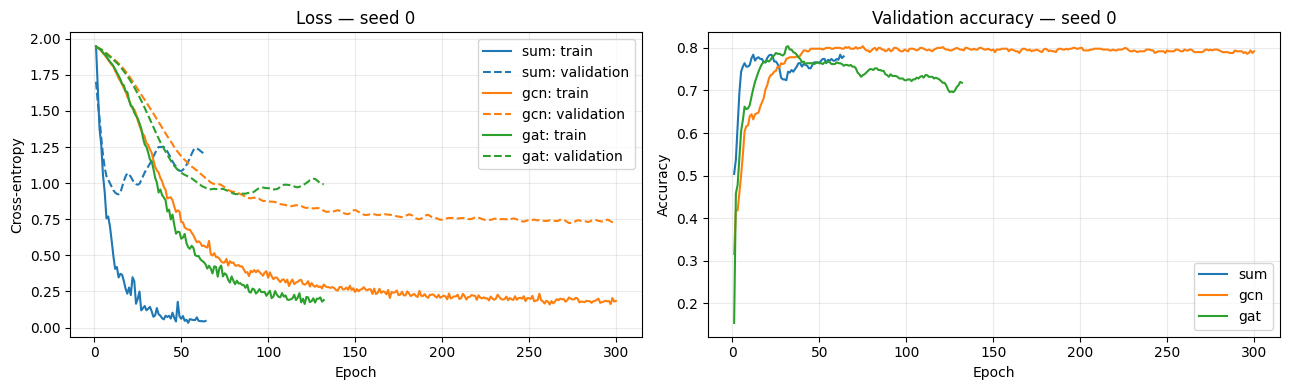

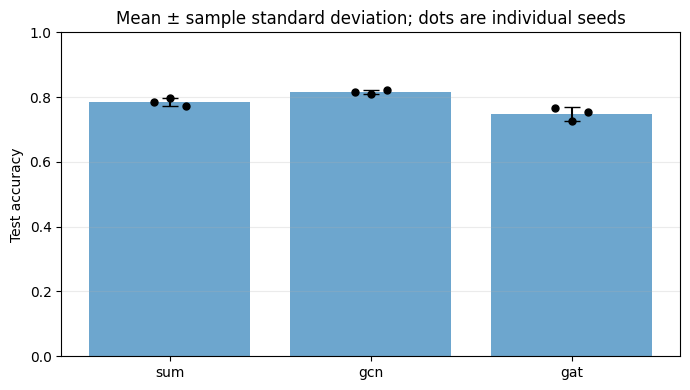

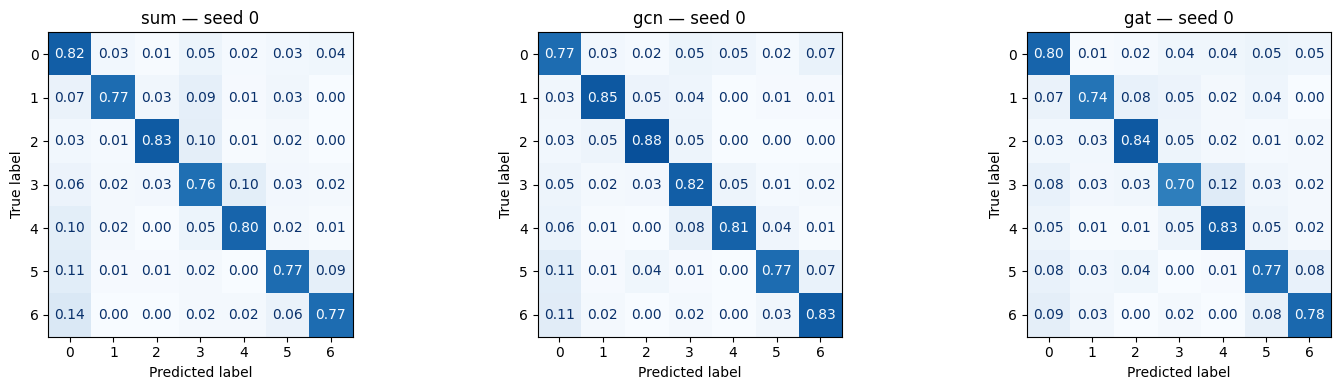

In [ ]:
PLOT_SEED = SEEDS[0]

plot_learning_curves(
    histories=histories,
    seed=PLOT_SEED,
    output_dir=OUTPUT_DIR,
)

plot_test_accuracy(
    results=results,
    output_dir=OUTPUT_DIR,
)

plot_confusion_matrices(
    predictions=predictions,
    seed=PLOT_SEED,
    num_classes=num_classes,
    output_dir=OUTPUT_DIR,
)

# MLP and CNN (without edges)

In [ ]:
import copy
import logging

import torch
from torch import nn
from torch.nn import functional as F

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
baseline_logger = logging.getLogger("feature_baselines")


class FeatureMLP(nn.Module):
    """Classify nodes independently using only their feature vectors."""

    def __init__(self, in_channels, hidden_channels, out_channels, dropout=0.5):
        """Configure the input, hidden, and output dimensions."""
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(in_channels, hidden_channels),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_channels, out_channels),
        )

    def forward(self, x, edge_index=None):
        """Return class logits; edge_index is accepted but deliberately unused."""
        return self.network(x)


class FeatureCNN(nn.Module):
    """Apply 1D convolution across each node's ordered feature vector."""

    def __init__(self, in_channels, hidden_channels, out_channels, dropout=0.5):
        """Configure a CNN for feature vectors of length in_channels."""
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),
            nn.Conv1d(16, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),
        )

        # Retain feature positions rather than averaging away word identity.
        pooled_length = in_channels // 4
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * pooled_length, hidden_channels),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_channels, out_channels),
        )

    def forward(self, x, edge_index=None):
        """Return logits from [nodes, features]; graph edges are ignored."""
        # Nodes form the batch dimension, not the convolution dimension.
        x = x.unsqueeze(1)  # [nodes, 1, features]
        return self.classifier(self.features(x))

In [ ]:
def train_feature_baseline(
    model, graph, epochs=200, lr=0.01, weight_decay=5e-4, log_every=25
):
    """Train on one-dimensional masks and restore the best validation checkpoint.

    Mutates model parameters. Returns validation and test accuracies for the
    checkpoint with the lowest validation loss. Assumes nonempty masks.
    """
    if epochs < 1 or log_every < 1:
        raise ValueError("epochs and log_every must be positive.")

    name = type(model).__name__
    optimizer = torch.optim.Adam(
        model.parameters(), lr=lr, weight_decay=weight_decay
    )
    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0

    baseline_logger.info("Starting %s: %d epochs", name, epochs)

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()

        logits = model(graph.x)
        train_loss = F.cross_entropy(
            logits[graph.train_mask], graph.y[graph.train_mask]
        )
        train_loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            logits = model(graph.x)
            val_loss = F.cross_entropy(
                logits[graph.val_mask], graph.y[graph.val_mask]
            ).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch

        if epoch == 1 or epoch % log_every == 0 or epoch == epochs:
            baseline_logger.info(
                "%s | epoch %d | train loss %.4f | val loss %.4f",
                name, epoch, train_loss.item(), val_loss,
            )

    if best_state is None:
        raise RuntimeError(f"{name}: no finite validation checkpoint was found.")

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        predictions = model(graph.x).argmax(dim=1)
        val_accuracy = (
            predictions[graph.val_mask] == graph.y[graph.val_mask]
        ).float().mean().item()
        test_accuracy = (
            predictions[graph.test_mask] == graph.y[graph.test_mask]
        ).float().mean().item()

    baseline_logger.info(
        "%s complete | best epoch %d | validation %.2f%% | test %.2f%%",
        name, best_epoch, 100 * val_accuracy, 100 * test_accuracy,
    )
    return {
        "best_epoch": best_epoch,
        "val_accuracy": val_accuracy,
        "test_accuracy": test_accuracy,
    }

In [ ]:
# Stay on the existing data's device; do not reload or modify the graph.
baseline_device = data.x.device
num_features = data.x.size(1)
num_classes = int(data.y.max().item()) + 1

feature_models = {}
feature_results = {}

for name, model_class in {"MLP": FeatureMLP, "CNN": FeatureCNN}.items():
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    model = model_class(
        in_channels=num_features,
        hidden_channels=64,
        out_channels=num_classes,
        dropout=0.5,
    ).to(baseline_device)

    feature_results[name] = train_feature_baseline(
        model, data, epochs=200, lr=0.01, weight_decay=5e-4
    )
    feature_models[name] = model

print("\nFeature-only comparison")
print(f"{'Model':<10} {'Validation':>12} {'Test':>12}")
for name, metrics in feature_results.items():
    print(
        f"{name:<10} "
        f"{metrics['val_accuracy']:>11.2%} "
        f"{metrics['test_accuracy']:>12.2%}"
    )

11:14:58 | INFO | Starting FeatureMLP: 200 epochs
11:14:58 | INFO | FeatureMLP | epoch 1 | train loss 1.9505 | val loss 1.9142
11:14:59 | INFO | FeatureMLP | epoch 25 | train loss 1.1435 | val loss 1.7088
11:15:00 | INFO | FeatureMLP | epoch 50 | train loss 0.2690 | val loss 1.3920
11:15:02 | INFO | FeatureMLP | epoch 75 | train loss 0.2085 | val loss 1.3155
11:15:03 | INFO | FeatureMLP | epoch 100 | train loss 0.1555 | val loss 1.2949
11:15:04 | INFO | FeatureMLP | epoch 125 | train loss 0.1295 | val loss 1.2960
11:15:05 | INFO | FeatureMLP | epoch 150 | train loss 0.1227 | val loss 1.2836
11:15:06 | INFO | FeatureMLP | epoch 175 | train loss 0.1046 | val loss 1.2817
11:15:07 | INFO | FeatureMLP | epoch 200 | train loss 0.1167 | val loss 1.2715
11:15:07 | INFO | FeatureMLP complete | best epoch 195 | validation 58.60% | test 60.40%
11:15:07 | INFO | Starting FeatureCNN: 200 epochs
11:15:14 | INFO | FeatureCNN | epoch 1 | train loss 1.9486 | val loss 2.1587
11:17:54 | INFO | FeatureCNN